In [1]:
!pip install tqdm pillow opencv-python

In [2]:
# ================== Autoencoder Semi-Supervised CIFAR-100 ==================
import random, os
from pathlib import Path
from typing import Tuple
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import save_image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
from tqdm import tqdm

# ---------------- Config ----------------
IMG_SIZE = 32
LATENT_DIM = 128          # smaller latent for faster training on Colab
BATCH_AE  = 128
BATCH_CLF = 128
AE_EPOCHS = 15            # keep short; you can raise later
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = Path("/content/outputs"); OUT_DIR.mkdir(exist_ok=True)
LABELED_PER_CLASS = 50

def seed_all(s=42):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(7)

# --------------- Data ---------------
tf = transforms.Compose([transforms.ToTensor()])
train_full = datasets.CIFAR100(root="/content/data", train=True, download=True, transform=tf)
test_full  = datasets.CIFAR100(root="/content/data", train=False, download=True, transform=tf)

lion_idx  = train_full.class_to_idx["lion"]
tiger_idx = train_full.class_to_idx["tiger"]

def pick_first_k(ds, class_idx, k):
    return [i for i, y in enumerate(ds.targets) if y == class_idx][:k]

k = LABELED_PER_CLASS
labeled_idx = pick_first_k(train_full, lion_idx, k) + pick_first_k(train_full, tiger_idx, k)
labeled_train = Subset(train_full, labeled_idx)
eval_idx = [i for i, y in enumerate(test_full.targets) if y in [lion_idx, tiger_idx]]
labeled_eval = Subset(test_full, eval_idx)
ae_train = train_full

def make_loader(ds, bs, shuffle=True):
    return DataLoader(ds, batch_size=bs, shuffle=shuffle, num_workers=2)

ae_loader  = make_loader(ae_train, BATCH_AE, True)
lbl_loader = make_loader(labeled_train, BATCH_CLF, True)
evl_loader = make_loader(labeled_eval,  BATCH_CLF, False)

# --------------- Model ---------------
class Encoder(nn.Module):
    def __init__(self, latent=LATENT_DIM):
        super().__init__()
        ch = 32
        self.net = nn.Sequential(
            nn.Conv2d(3, ch, 3, 2, 1), nn.ReLU(True),
            nn.Conv2d(ch, ch*2, 3, 2, 1), nn.BatchNorm2d(ch*2), nn.ReLU(True),
            nn.Conv2d(ch*2, ch*4, 3, 2, 1), nn.BatchNorm2d(ch*4), nn.ReLU(True),
        )
        self.fc = nn.Linear(ch*4*4*4, latent)
    def forward(self, x):
        h = self.net(x)
        h = h.view(h.size(0), -1)
        return self.fc(h)

class Decoder(nn.Module):
    def __init__(self, latent=LATENT_DIM):
        super().__init__()
        ch = 128
        self.fc = nn.Linear(latent, ch*4*4)
        self.up = nn.Sequential(
            nn.ConvTranspose2d(ch, ch//2, 4, 2, 1), nn.BatchNorm2d(ch//2), nn.ReLU(True),
            nn.ConvTranspose2d(ch//2, ch//4, 4, 2, 1), nn.BatchNorm2d(ch//4), nn.ReLU(True),
            nn.ConvTranspose2d(ch//4, 3, 4, 2, 1), nn.Sigmoid()
        )
    def forward(self, z):
        h = self.fc(z).view(-1, 128, 4, 4)
        return self.up(h)

class AutoEncoder(nn.Module):
    def __init__(self, latent=LATENT_DIM):
        super().__init__()
        self.encoder = Encoder(latent)
        self.decoder = Decoder(latent)
    def forward(self, x):
        z = self.encoder(x)
        xr = self.decoder(z)
        return xr, z

# --------------- Train AE ---------------
ae = AutoEncoder(LATENT_DIM).to(DEVICE)
opt = torch.optim.Adam(ae.parameters(), lr=2e-3)
for epoch in range(1, AE_EPOCHS+1):
    ae.train(); losses = []
    for x, _ in tqdm(ae_loader, desc=f"AE {epoch}/{AE_EPOCHS}"):
        x = x.to(DEVICE)
        xr, _ = ae(x)
        loss = F.l1_loss(xr, x) + 0.1*F.mse_loss(xr, x)
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    print(f"AE loss: {sum(losses)/len(losses):.4f}")
    if epoch % 5 == 0:
        save_image(xr[:16].cpu(), OUT_DIR/f"recon_e{epoch}.png", nrow=8)

# --------------- Feature extraction ---------------
encoder = ae.encoder.eval()
for p in encoder.parameters(): p.requires_grad = False

def collect_feats(loader):
    feats, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            y = torch.where(y==lion_idx, torch.tensor(0), torch.tensor(1))
            z = encoder(x.to(DEVICE)).cpu().numpy()
            feats.append(z); labels.append(y.numpy())
    return np.concatenate(feats), np.concatenate(labels)

Xtr, ytr = collect_feats(lbl_loader)
Xte, yte = collect_feats(evl_loader)

# --------------- Classifier ---------------
clf = LogisticRegression(max_iter=2000, n_jobs=-1)
clf.fit(Xtr, ytr)
pred = clf.predict(Xte)

print("\n=== Lion vs Tiger (AE features + Logistic Regression) ===")
print(f"Accuracy: {accuracy_score(yte, pred):.4f}")
print(classification_report(yte, pred, target_names=['lion','tiger']))
print(f"Reconstructions saved in {OUT_DIR}")

100%|██████████| 169M/169M [00:02<00:00, 59.2MB/s]
AE 1/15: 100%|██████████| 391/391 [01:26<00:00,  4.53it/s]


AE loss: 0.1035


AE 2/15: 100%|██████████| 391/391 [01:26<00:00,  4.50it/s]


AE loss: 0.0712


AE 3/15: 100%|██████████| 391/391 [01:26<00:00,  4.52it/s]


...

AE 14/15: 100%|██████████| 391/391 [01:28<00:00,  4.44it/s]


AE loss: 0.0493


AE 15/15: 100%|██████████| 391/391 [01:27<00:00,  4.46it/s]

AE loss: 0.0492



=== Lion vs Tiger (AE features + Logistic Regression) ===
Accuracy: 0.5650
              precision    recall  f1-score   support

        lion       0.56      0.61      0.58       100
       tiger       0.57      0.52      0.54       100

    accuracy                           0.56       200
   macro avg       0.57      0.56      0.56       200
weighted avg       0.57      0.56      0.56       200

Reconstructions saved in /content/outputs


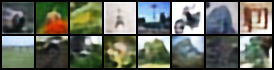

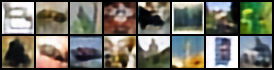

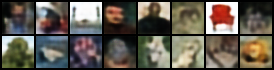

In [3]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob("/content/outputs/recon_*.png")):
    display(Image(filename=f))

In [4]:
# To potentially improve results, you could try increasing these values
# and re-running the main training cell (Cell 2) above.
# Note: Increasing AE_EPOCHS will significantly increase training time.

# AE_EPOCHS = 40      # more training time
# LATENT_DIM = 256    # larger latent space
# LABELED_PER_CLASS = 100  # more labeled samples for the final classifier

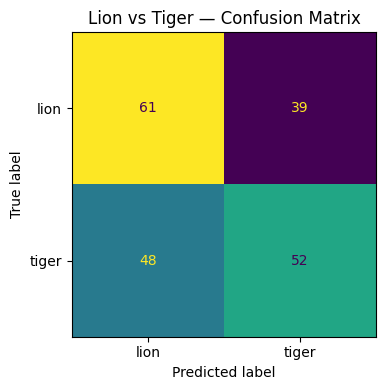

              precision    recall  f1-score   support

        lion       0.56      0.61      0.58       100
       tiger       0.57      0.52      0.54       100

    accuracy                           0.56       200
   macro avg       0.57      0.56      0.56       200
weighted avg       0.57      0.56      0.56       200



In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# assumes you already have: yte, pred from running Cell 2
cm = confusion_matrix(yte, pred, labels=[0,1])
disp = ConfusionMatrixDisplay(cm, display_labels=["lion","tiger"])
fig, ax = plt.subplots(figsize=(4,4))
disp.plot(ax=ax, values_format='d', colorbar=False)
plt.title("Lion vs Tiger — Confusion Matrix")
plt.tight_layout()
plt.show()

# It also re-prints the classification report for convenience
print(classification_report(yte, pred, target_names=["lion","tiger"]))

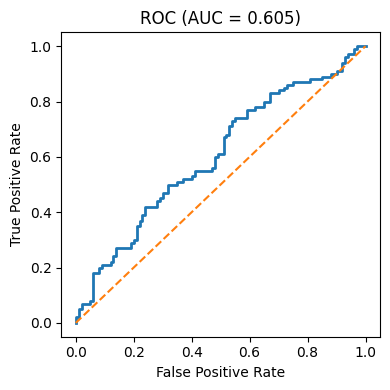

In [6]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# assumes clf, Xte, yte are available from Cell 2
# need probabilities; LogisticRegression supports predict_proba
proba = clf.predict_proba(Xte)[:,1]   # prob(tiger)
fpr, tpr, _ = roc_curve(yte, proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(4,4))
plt.plot(fpr, tpr, lw=2)
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title(f"ROC (AUC = {roc_auc:.3f})")
plt.tight_layout(); plt.show()

Misclassified: 87


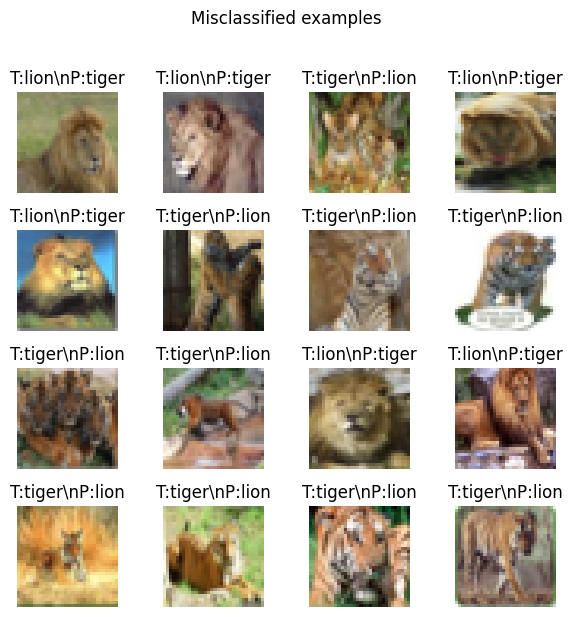

In [7]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Re-collect test features AND images to align predictions with pictures
# Assumes ae_loader, lion_idx, tiger_idx, encoder, DEVICE, clf from Cell 2 are available

def collect_feats_imgs(loader):
    feats, labels, imgs = [], [], []
    with torch.no_grad():
        for x, y in loader:
            y_bin = torch.where(y==lion_idx, torch.tensor(0), torch.tensor(1))
            z = encoder(x.to(DEVICE)).cpu().numpy()
            feats.append(z); labels.append(y_bin.numpy()); imgs.append(x.numpy())
    return (np.concatenate(feats), np.concatenate(labels),
            np.concatenate(imgs))

Xte2, yte2, imgs = collect_feats_imgs(evl_loader)
pred2 = clf.predict(Xte2)

wrong = np.where(pred2 != yte2)[0]
print(f"Misclassified: {len(wrong)}")

# show up to 16 mistakes
n = min(16, len(wrong))
plt.figure(figsize=(6,6))
for i, idx in enumerate(wrong[:n]):
    plt.subplot(4,4,i+1)
    # Transpose image dimensions from (C, H, W) to (H, W, C) for matplotlib
    plt.imshow(np.transpose(imgs[idx], (1,2,0)))
    plt.axis('off')
    plt.title(f"T:{['lion','tiger'][yte2[idx]]}\\nP:{['lion','tiger'][pred2[idx]]}")
plt.suptitle("Misclassified examples", y=1.02, fontsize=12)
plt.tight_layout(); plt.show()

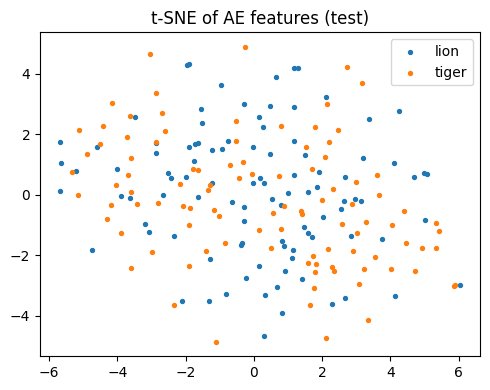

In [8]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

# Assumes Xte, yte from Cell 2 are available
tsne = TSNE(n_components=2, init="pca", random_state=0, perplexity=30, learning_rate='auto')
Z2 = tsne.fit_transform(Xte)   # Xte are AE features
plt.figure(figsize=(5,4))
plt.scatter(Z2[yte==0,0], Z2[yte==0,1], s=8, label="lion")
plt.scatter(Z2[yte==1,0], Z2[yte==1,1], s=8, label="tiger")
plt.legend(); plt.title("t-SNE of AE features (test)")
plt.tight_layout(); plt.show()